In [18]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats

# 1. Setup path and list all parquet files
data_dir = Path("/groups/cns/share/Vincent/loren_frank/mr_analysis_with_new_pipeline/")
file_list = list(data_dir.glob("*.parquet"))

# 2. Parse filenames into a helper DataFrame
file_data = []
for f in file_list:
    parts = f.stem.split('_')
    # Pattern: name_area_session_day_session-number_timechunk
    # Check if it's a sleep session and has enough parts to be valid
    if len(parts) >= 5 and parts[2] == 'sleep' and parts[1] in ('CA1', 'CA2', 'CA3'):
        file_data.append({
            'file_path': f,
            'name': parts[0],
            'area': parts[1],
            'day': parts[3],
            'session_num': int(parts[4]),
            'timechunk': parts[5]
        })

df_files = pd.DataFrame(file_data)

# 3. Rank sessions chronologically per Animal-Area-Day
# This turns sleep_03, sleep_05 into 1, 2 regardless of the specific gap
df_files['session_idx'] = (
    df_files.groupby(['name', 'area', 'day'])['session_num']
    .rank(method='dense')
    .astype(int)
)

# 4. Load data and combine
final_rows = []
for _, row in df_files.iterrows():
    try:
        temp_df = pd.read_parquet(row['file_path'])
        final_rows.append({
            'name': row['name'],
            'area': row['area'],
            'day': row['day'],
            'session_idx': row['session_idx'],
            'tau': temp_df['tau'].iloc[0],
            'num_neurons': temp_df['num_neurons'].iloc[0]
        })
    except Exception as e:
        print(f"Error loading {row['file_path']}: {e}")

result_df = pd.DataFrame(final_rows)
result_df = result_df[result_df['tau'] < 3000]


<Figure size 1200x600 with 0 Axes>

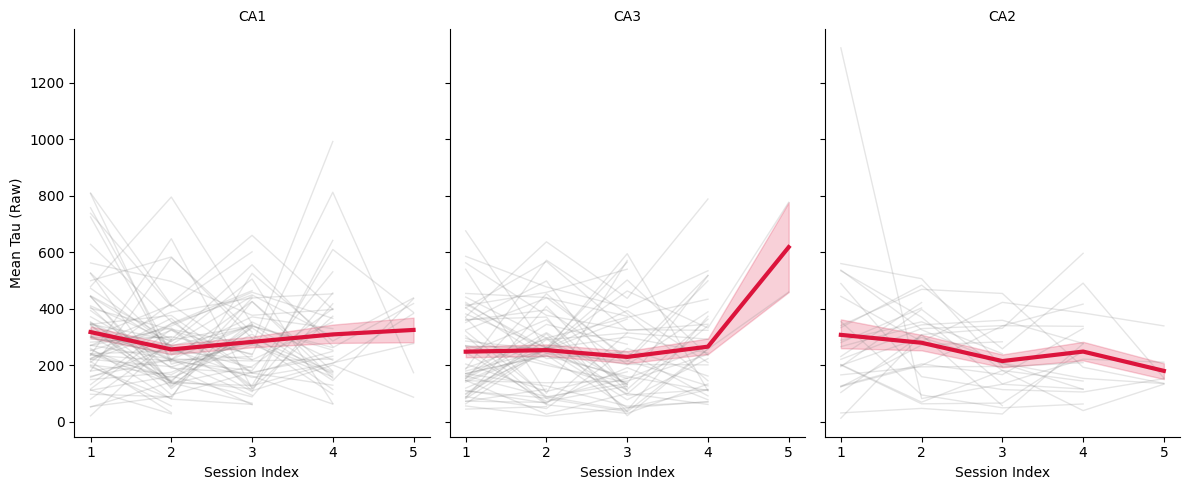

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate: Average Tau across timechunks for each session
df_plot = result_df.groupby(['name', 'day', 'area', 'session_idx'])['tau'].mean().reset_index()

# 2. Create a unique identifier for each 'Animal-Day' to connect lines
df_plot['day_id'] = df_plot['name'] + "_" + df_plot['day']

# 3. Create the Visualization
# IMPORTANT: sharey=True ensures all subplots have the same Y-axis scale
plt.figure(figsize=(12, 6))
g = sns.FacetGrid(df_plot, col="area", height=5, aspect=0.8, col_wrap=3, sharey=True)

# Step A: Draw individual day lines in the background (Light Grey)
g.map_dataframe(sns.lineplot, x="session_idx", y="tau", units="day_id", 
                estimator=None, color="grey", alpha=0.2, linewidth=1)

# Step B: Draw the Mean Trend line on top (Bold Color)
# errorbar=('ci', 68) calculates the Standard Error of the Mean (SEM)
g.map_dataframe(sns.lineplot, x="session_idx", y="tau", 
                color="crimson", linewidth=3, errorbar=('ci', 68))

# 4. Formatting
g.set_axis_labels("Session Index", "Mean Tau (Raw)")
g.set_titles(col_template="{col_name}")

# Standardize the X-ticks to the actual session indices found in data
unique_sessions = sorted(df_plot['session_idx'].unique())
for ax in g.axes:
    ax.set_xticks(unique_sessions)

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `session_idx` for `x`. An entry with this name does not appear in `data`.

<Figure size 1200x600 with 0 Axes>

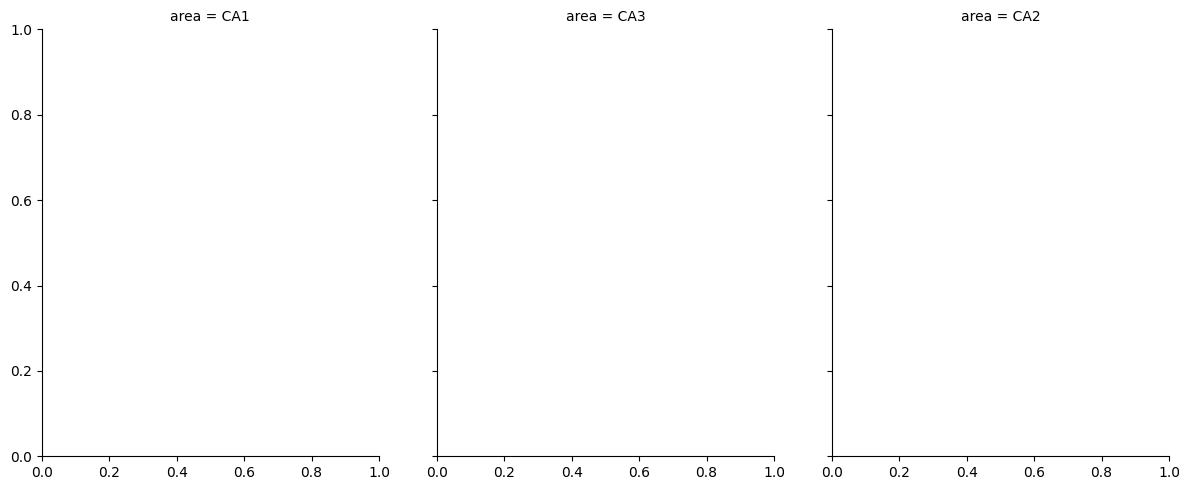

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure data is aggregated and Z-standardized (following previous step)
df_plot = result_df.groupby(['name', 'day', 'area', 'session_idx'])['tau'].mean().reset_index()
df_plot['tau_z'] = df_plot.groupby(['name', 'day', 'area'])['tau'].transform(
    lambda x: (x - x.mean()) / x.std() if len(x) > 1 and x.std() != 0 else 0
)
df_plot['day_id'] = df_plot['name'] + "_" + df_plot['day']

# 2. Create the Figure
plt.figure(figsize=(12, 6))

# We use a FacetGrid to separate by brain area
g = sns.FacetGrid(df_plot, col="area", height=5, aspect=0.8, col_wrap=3)

# Step A: Draw individual day lines in the background (light alpha)
# 'units' tells seaborn to treat each day_id as a separate line
# 'estimator=None' prevents it from averaging them yet
g.map_dataframe(sns.lineplot, x="session_idx", y="tau_z", units="day_id", 
                estimator=None, color="grey", alpha=0.2, linewidth=1)

# Step B: Draw the Mean Trend line on top
# By default, sns.lineplot calculates the mean and a 95% confidence interval.
# Here we change 'ci' to 68 to show the Standard Error of the Mean (SEM).
g.map_dataframe(sns.lineplot, x="session_idx", y="tau_z", 
                color="teal", linewidth=3, ci=68)

# Step C: Add a reference line at 0 (the mean)
g.map(plt.axhline, y=0, color='black', linestyle='--', alpha=0.4)

# 3. Formatting
g.set_axis_labels("Session Index", "Tau (Z-Score)")
g.set_titles(col_template="{col_name}")
for ax in g.axes:
    ax.set_xticks([1, 2]) # Assuming session 1 and 2

plt.tight_layout()
plt.show()